# Dimensionality Reduction and Clustering

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [2]:
np.random.seed(42)
(images, labels), (test_images, test_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [3]:
images.shape

(60000, 28, 28)

In [4]:
labels.shape

(60000,)

In [5]:
test_images.shape

(10000, 28, 28)

In [6]:
X_train, _, y_train, _ = train_test_split(images, labels, train_size=3000, stratify=labels, random_state=42)
X_test, _, y_test, _ = train_test_split(test_images, test_labels, train_size=500, stratify=test_labels, random_state=42)
A = X_train.reshape(len(X_train), -1) / 255.0
B = X_test.reshape(len(X_test), -1) / 255.0
print(A.shape, B.shape)

(3000, 784) (500, 784)


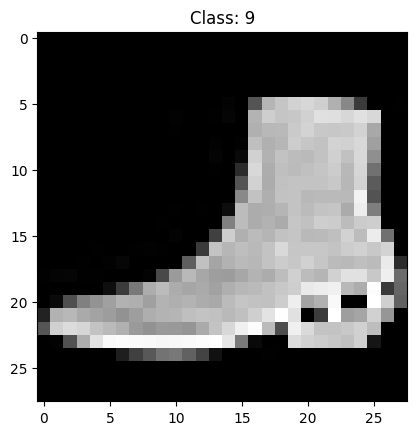

In [7]:
plt.imshow(X_train[0], cmap='gray')
plt.title(f'Class: {y_train[0]}')
plt.show()

## 1. Curse of dimensionality
**Goal:** Observe how adding irrelevant features can harm a distance-based classifier. Use the same train/test samples before and after adding noise.

In [8]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(A, y_train)
print('Original accuracy:', knn.score(B, y_test))

Original accuracy: 0.8


In [9]:
A_noise = np.column_stack((A, np.random.randn(len(A), 1000)))
B_noise = np.column_stack((B, np.random.randn(len(B), 1000)))
A_noise.shape

(3000, 1784)

In [10]:
knn.fit(A_noise, y_train)
print('With noise:', knn.score(B_noise, y_test))

With noise: 0.48


## 2. PCA on real data and component selection
**Goal:** Reduce 784 pixels to two components. Pixels are normalized to [0, 1]; PCA centers them automatically. Labels are only used for coloring.

In [11]:
pca = PCA(n_components=2)
Z_train = pca.fit_transform(A)
Z_test = pca.transform(B)
print('Before:', B.shape)
print('After:', Z_test.shape)

Before: (500, 784)
After: (500, 2)


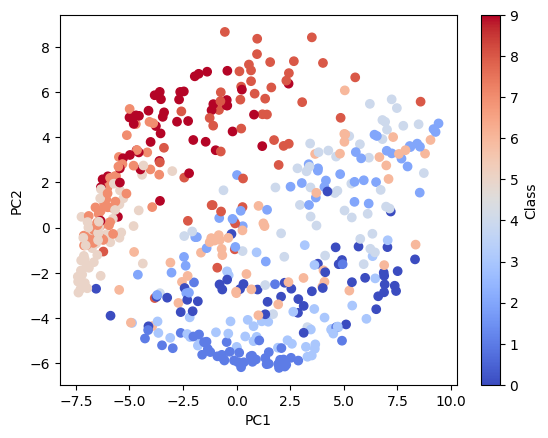

Retained variance: 0.4691619276422889


In [12]:
plt.scatter(Z_test[:, 0], Z_test[:, 1], c=y_test, cmap='coolwarm')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Class')
plt.show()
print('Retained variance:', pca.explained_variance_ratio_.sum())

In [13]:
pca95 = PCA(n_components=0.95)
Z95 = pca95.fit_transform(A)
print('Components for 95% variance:', pca95.n_components_)
print('Retained variance:', pca95.explained_variance_ratio_.sum())

Components for 95% variance: 169
Retained variance: 0.9501089313292983


## 3. PCA limitations
**Goal:** See why scale, correlation, duplicate features and outliers matter. A duplicate column adds no independent information.

In [14]:
M = np.array([[1, 2], [2, 1], [3, 4], [4, 3]])
M_large = M * [1, 1000]
print('Without scaling:', PCA().fit(M_large).explained_variance_ratio_)
print('With scaling:', PCA().fit(StandardScaler().fit_transform(M_large)).explained_variance_ratio_)

Without scaling: [9.9999936e-01 6.3999913e-07]
With scaling: [0.8 0.2]


In [15]:
M_duplicate = np.column_stack((M, M[:, 0]))
print('With duplicate:', PCA().fit(M_duplicate).explained_variance_ratio_)

With duplicate: [8.28295260e-01 1.71704740e-01 1.08758397e-34]


In [16]:
M_outlier = np.vstack((M, [30, 40]))
print('With outlier:', PCA().fit(M_outlier).explained_variance_ratio_)

With outlier: [0.99877112 0.00122888]


## 4. Prepare data for clustering
Reduce pixels to 20 features. Use the first two for plots. Labels are not used to fit clustering models.

In [17]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_moons

# Reduce 784 pixels to 20 features
cluster_pca = PCA(n_components=20, random_state=42)
F = cluster_pca.fit_transform(A)
print(F.shape)

(3000, 20)


## 5. K-Means: assignment and update
Start with two centers. Each point joins its closest center; each center moves to the mean of its group. Run the update cell again to see another round.

In [18]:
points = np.array([[2,6],[3,4],[3,8],[4,7],[6,2],[6,4],[7,3],[7,4],[8,5],[7,6]])
center1 = points[0].astype(float)
center2 = points[2].astype(float)

In [19]:
# Calculate distance to each center
distance1 = np.linalg.norm(points - center1, axis=1)
distance2 = np.linalg.norm(points - center2, axis=1)
# Assign points to their closest center
group1 = distance1 <= distance2
# Update the centers using the mean
center1 = points[group1].mean(axis=0)
center2 = points[~group1].mean(axis=0)
print(center1, center2)

[5.16666667 3.83333333] [5.5 6.5]


## 6. K-Means on Fashion-MNIST
Choose 10 clusters. Inertia is the sum of squared distances to assigned centers. Cluster numbers are not clothing class numbers.

Cluster sizes: [118 400 127 441 149 491 341 334 370 229]


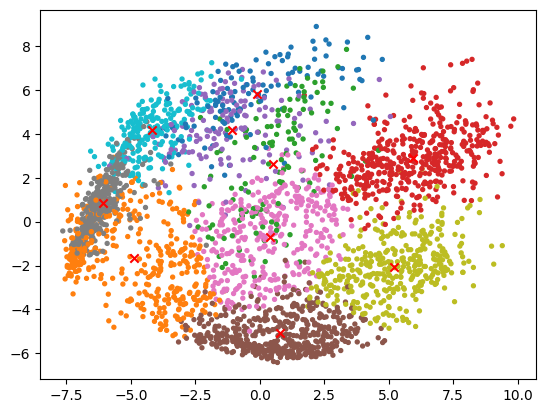

In [20]:
# Fit K-Means without labels
km = KMeans(n_clusters=10, n_init=10, random_state=42)
f_groups = km.fit_predict(F)
print('Cluster sizes:', np.bincount(f_groups))

# Display clusters using the first two PCA features
plt.scatter(F[:,0], F[:,1], c=f_groups, cmap='tab10', s=8)
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], marker='x', c='red')
plt.show()

## 7. K-Means limitations
Outliers pull the mean; curved groups are difficult for nearest-center clustering.

Original mean: [5.3 4.9]
With outlier: [7.54545455 8.09090909]


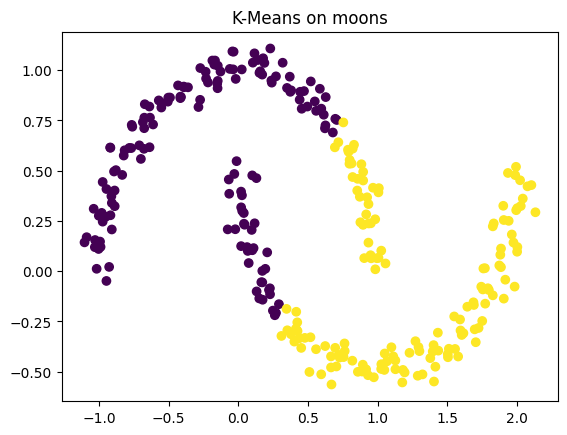

In [21]:
# Compare the mean before and after adding an outlier
print('Original mean:', points.mean(axis=0))
print('With outlier:', np.vstack([points, [30,40]]).mean(axis=0))

# Generate two curved groups
moons, _ = make_moons(n_samples=300, noise=0.05, random_state=42)
moon_km = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(moons)
plt.scatter(moons[:,0], moons[:,1], c=moon_km)
plt.title('K-Means on moons')
plt.show()

## 8. DBSCAN
eps is the neighborhood radius; min_samples includes the point itself. Core points have enough neighbors; border points belong to a cluster but are not core; noise has label -1.

Cluster labels: [ 0  0  0  0  1  1  1  1  1  1 -1]
Core point indices: [0 2 3 4 5 6 7 8 9]
Noise indices: [10]


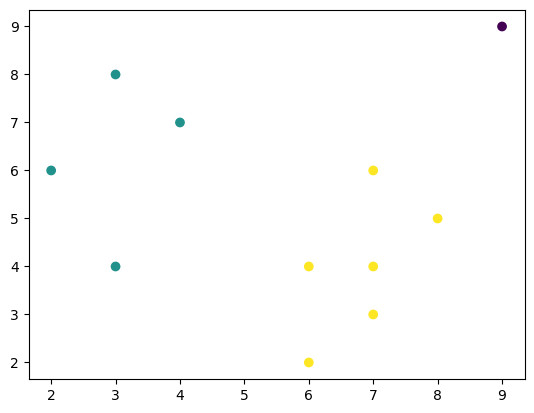

In [22]:
P = np.vstack([points, [9,9]])
db = DBSCAN(eps=2.5, min_samples=3)
db.fit(P)
print('Cluster labels:', db.labels_)
print('Core point indices:', db.core_sample_indices_)
print('Noise indices:', np.where(db.labels_ == -1)[0])
# Remaining non-noise points are border points
plt.scatter(P[:,0], P[:,1], c=db.labels_)
plt.show()

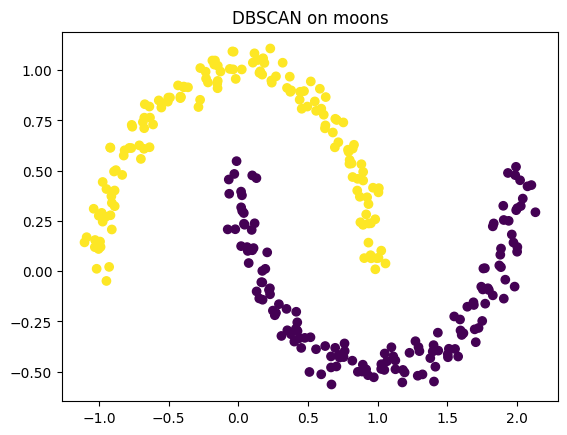

In [23]:
# Compare with K-Means on the same curved data
moon_db = DBSCAN(eps=0.18, min_samples=5).fit_predict(moons)
plt.scatter(moons[:,0], moons[:,1], c=moon_db)
plt.title('DBSCAN on moons')
plt.show()

## 9. DBSCAN on Fashion-MNIST
Use two standardized PCA features for this density demonstration. Change eps and rerun; small eps may produce more noise, large eps may merge groups. Different densities can be difficult to handle with one radius.

In [24]:
F

array([[-2.99191003e+00,  4.34422360e+00, -3.19312518e+00, ...,
        -2.45244649e-01, -4.08899703e-01, -1.68216995e-02],
       [-4.45819940e+00, -3.20197894e+00,  2.02133462e+00, ...,
        -3.23082456e-01, -1.56653874e-02, -1.89829831e-02],
       [-1.72080821e+00, -4.76713854e+00, -1.87808480e+00, ...,
        -6.58561749e-01, -2.79554161e-01, -2.70019799e-01],
       ...,
       [ 6.13687632e+00, -1.81632665e+00, -5.24958024e-01, ...,
        -1.01940120e+00,  5.04193774e-01,  3.54468365e-01],
       [-6.35188832e+00,  9.80287319e-01,  5.66003765e-01, ...,
        -7.79857021e-02,  2.97465051e-03, -3.62816444e-01],
       [ 5.06728474e+00,  2.71575971e+00,  2.35073482e+00, ...,
        -2.04640907e-01, -1.19321979e-01,  3.40432699e-01]],
      shape=(3000, 20))

In [25]:
F2 = StandardScaler().fit_transform(F[:,:2])
F2

array([[-0.67325943,  1.24214655],
       [-1.00321358, -0.91554383],
       [-0.38722767, -1.36307088],
       ...,
       [ 1.38096059, -0.51934341],
       [-1.42934401,  0.28029416],
       [ 1.140274  ,  0.77651886]], shape=(3000, 2))

Noise points: 121
Labels: [-1  0  1]


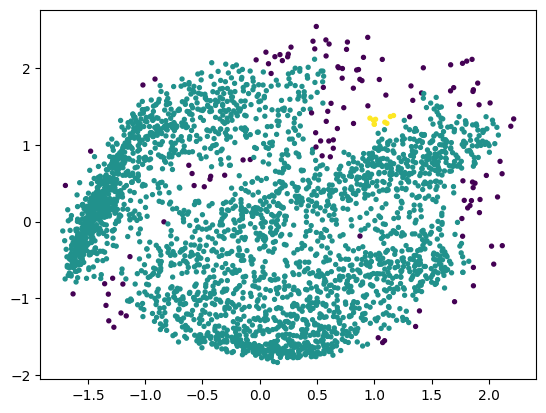

In [26]:
f_db = DBSCAN(eps=0.15, min_samples=10).fit_predict(F2)
print('Noise points:', np.sum(f_db == -1))
print('Labels:', np.unique(f_db))
plt.scatter(F2[:,0], F2[:,1], c=f_db, s=8)
plt.show()

## practice — Digits
Apply the same ideas to 1,797 handwritten digit images (8 × 8 pixels, 64 features, 10 classes).

(1257, 64) (540, 64)


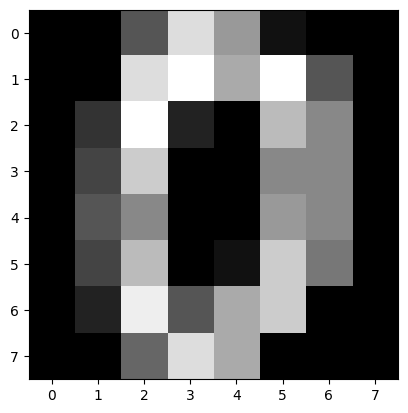

In [27]:
digits = load_digits()
Xd = digits.data / 16.0
yd = digits.target
Ad, Bd, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.3, random_state=42, stratify=yd)
print(Ad.shape, Bd.shape)
plt.imshow(digits.images[0], cmap='gray')
plt.show()

### Task 1 — PCA
Reduce Digits to two components, plot the test samples by class, and find the number of components needed for 90% variance.

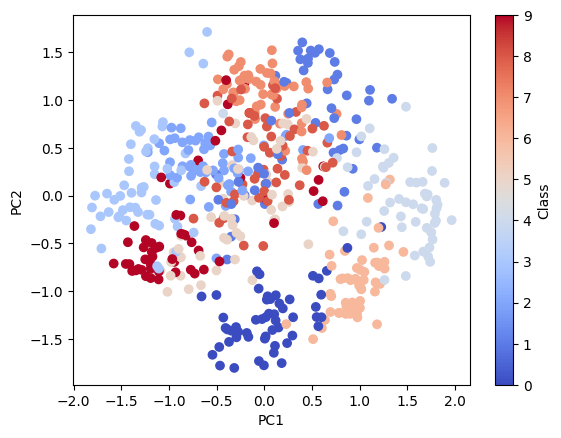

Retained variance: 0.28290769420152967


In [28]:
pca = PCA(n_components=2, random_state=42)
A_pca = pca.fit_transform(Ad)
B_pca = pca.transform(Bd)

plt.scatter(B_pca[:, 0], B_pca[:, 1], c=yd_test, cmap='coolwarm')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Class')
plt.show()
print('Retained variance:', pca.explained_variance_ratio_.sum())

In [30]:
pca90 = PCA(n_components=0.90, random_state=42)

A_pca90 = pca90.fit_transform(Ad)
print('Number of Components for 90% variance:', pca90.n_components_)

Number of Components for 90% variance: 21


### Task 2 — K-Means
Reduce Digits to 20 features and cluster into 10 groups.

Cluster sizes: [131 137 114 130 125  96 191 116 150  67]


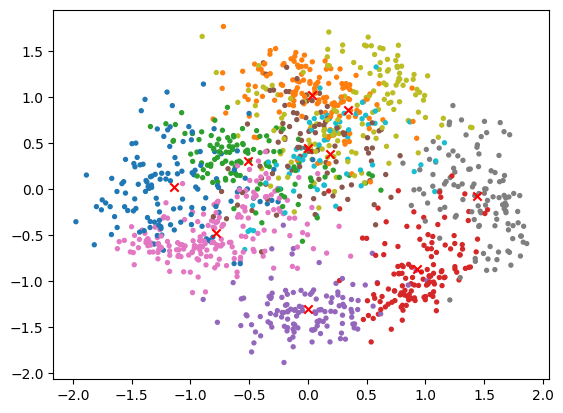

In [31]:
pca20 = PCA(n_components=20, random_state=42)
A_pca20 = pca20.fit_transform(Ad)

km = KMeans(n_clusters=10, random_state=42, n_init=10)
A_groups = km.fit_predict(A_pca20)

print('Cluster sizes:', np.bincount(A_groups))

plt.scatter(A_pca20[:,0], A_pca20[:,1], c=A_groups, cmap='tab10', s=8)
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], marker='x', c='red')
plt.show()

### Task 3 — DBSCAN
Try eps=0.2 and then 0.4. Compare noise counts. Also try changing min_samples.

In [44]:
db = DBSCAN(eps=0.2, min_samples=10)
db.fit(StandardScaler().fit_transform(A_pca))
print('Noise Count:', np.where(db.labels_ == -1)[0].sum())

Noise Count: 72636


In [45]:
db = DBSCAN(eps=0.4, min_samples=10)
db.fit(StandardScaler().fit_transform(A_pca))
print('Noise indices:', np.where(db.labels_ == -1)[0].sum())

Noise indices: 364
